# 02 – K-means: klustring av klagomålstexter

Den här notebooken bygger vidare på den rensade datan från `01_eda.ipynb` (`data/complaints_clean.parquet`, 101 373 klagomål). K-means används som **baslinje** och jämförs senare med LDA (`03_lda.ipynb`) och HDBSCAN (`04_hdbscan.ipynb`).

**Upplägg:**
1. Representation av texterna (TF-IDF + dimensionsreduktion med TruncatedSVD)
2. Val av antal kluster (elbow-metoden, silhouette score och tolkningsbarhet)
3. Tolkning och namngivning av de 14 klustren
4. Statistiskt test: skiljer sig chansen att få hjälp mellan ärendetyperna? (chi² och Cramér's V)

**Resultat sparas i:** `data/complaints_kmeans.parquet` (rensad data + kolumnerna `kluster14` och `arendetyp`)

Alla slumpmässiga steg använder `random_state=42` så att resultaten går att återskapa.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS

df = pd.read_parquet("../data/complaints_clean.parquet")
print("Antal klagomål:", len(df))

foretagsnamn = {
    "wells", "fargo", "chase", "jpmorgan", "paypal", "capital", "affirm",
    "mohela", "navient", "nelnet", "citi", "citibank", "synchrony",
    "amex", "barclays", "coinbase", "santander", "ally", "truist",
    "america", "venmo",
}
klagomalsord = {
    "told", "called", "received", "did", "company", "consumer",
    "information", "said", "asked", "stated", "contacted",
}
stoppord = list(ENGLISH_STOP_WORDS | foretagsnamn | klagomalsord)

vec = TfidfVectorizer(stop_words=stoppord, min_df=20, max_df=0.5)
X = vec.fit_transform(df["text_clean"])
print("Matrisens storlek:", X.shape)

Antal klagomål: 101373
Matrisens storlek: (101373, 9189)


## 1. Dimensionsreduktion med TruncatedSVD

TF-IDF ger varje text över 9 000 kolumner, en per ord, och nästan alla är noll. K-means fungerar dåligt med så många dimensioner, eftersom avstånden mellan texter blir nästan lika stora (det så kallade dimensionsproblemet).

Därför komprimeras texterna till 100 dimensioner med **TruncatedSVD**. Enkelt förklarat hittar metoden grupper av ord som ofta förekommer tillsammans, t.ex. *mortgage, escrow, insurance*, och slår ihop dem till gemensamma "teman". Varje text beskrivs sedan av hur mycket den handlar om varje tema. Tekniken kallas inom textanalys för *Latent Semantic Analysis (LSA)*.

Efter komprimeringen normaliseras varje text till längd 1, så att det är textens *innehåll* och inte dess längd som avgör vilket kluster den hamnar i.

In [2]:
from sklearn.decomposition import TruncatedSVD
from sklearn.preprocessing import Normalizer
from sklearn.pipeline import make_pipeline

lsa = make_pipeline(TruncatedSVD(n_components=100, random_state=42), Normalizer(copy=False))
X_lsa = lsa.fit_transform(X)

forklarad = lsa[0].explained_variance_ratio_.sum()
print("Ny storlek:", X_lsa.shape)
print(f"Förklarad varians med 100 dimensioner: {forklarad:.1%}")

Ny storlek: (101373, 100)
Förklarad varians med 100 dimensioner: 23.2%


## 2. Val av antal kluster

K-means kräver att antalet kluster (k) bestäms i förväg. Två mått används:

- **Elbow-metoden (inertia):** mäter hur nära texterna ligger sitt klustercentrum. Värdet minskar alltid när k ökar, men man letar efter en "armbåge" där förbättringen planar ut.
- **Silhouette score (−1 till 1):** mäter hur väl varje text passar i sitt eget kluster jämfört med närmaste andra kluster. Högre är bättre.

Silhouette beräknas på ett slumpmässigt urval av 10 000 texter, eftersom beräkningen annars blir för tung.

k= 4  inertia=79,644  silhouette=0.049
k= 6  inertia=76,863  silhouette=0.049
k= 8  inertia=74,589  silhouette=0.050
k=10  inertia=72,759  silhouette=0.057
k=12  inertia=71,305  silhouette=0.059
k=14  inertia=69,874  silhouette=0.063
k=16  inertia=68,662  silhouette=0.062
k=18  inertia=67,717  silhouette=0.065
k=20  inertia=66,632  silhouette=0.068


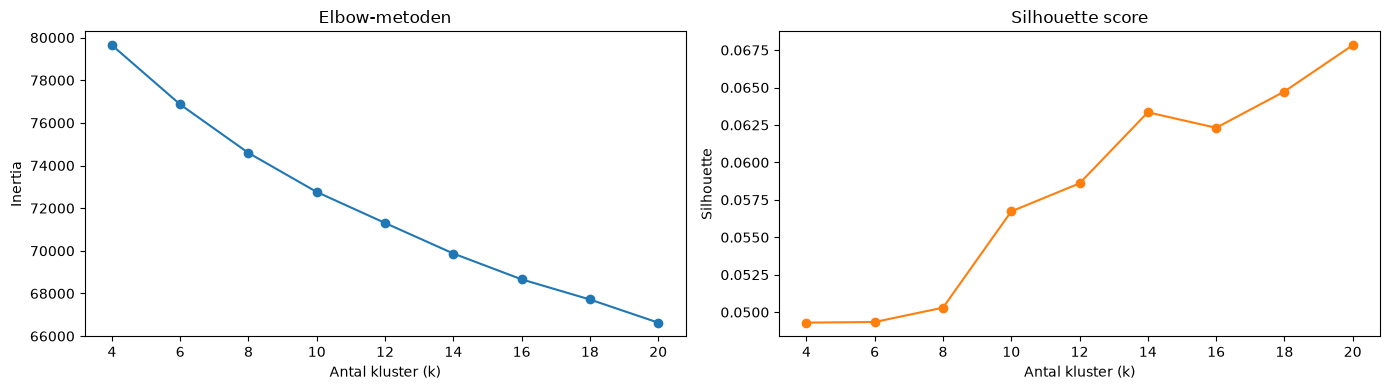

In [3]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_varden = range(4, 21, 2)
inertia = []
silhouette = []

for k in k_varden:
    km = KMeans(n_clusters=k, n_init=5, random_state=42)
    etiketter = km.fit_predict(X_lsa)
    inertia.append(km.inertia_)
    silhouette.append(silhouette_score(X_lsa, etiketter, sample_size=10_000, random_state=42))
    print(f"k={k:2d}  inertia={km.inertia_:,.0f}  silhouette={silhouette[-1]:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].plot(list(k_varden), inertia, marker="o")
axes[0].set_title("Elbow-metoden")
axes[0].set_xlabel("Antal kluster (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(list(k_varden), silhouette, marker="o", color="tab:orange")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Antal kluster (k)")
axes[1].set_ylabel("Silhouette")

plt.tight_layout()
plt.show()

**Resultat – val av k:**

- **Ingen tydlig armbåge.** Inertia minskar jämnt från 79 600 (k=4) till 66 600 (k=20), utan någon punkt där förbättringen tydligt planar ut.
- **Silhouette är lågt för alla k** (0,049–0,068) och ökar nästan genomgående med fler kluster. Låga värden är väntade för text: klagomål överlappar naturligt, t.ex. kan samma text handla om både bedrägeri och avgifter.
- **Det enda tydliga hoppet** sker mellan k=8 och k=10 (0,050 → 0,057).

**Slutsats:** måtten räcker inte för att välja k. Valet görs därför också utifrån **tolkningsbarhet och användbarhet**: klustren ska gå att beskriva i klarspråk, och antalet ska vara hanterbart för en kundserviceorganisation. k=10 och k=14 jämförs genom att granska de mest utmärkande orden i varje kluster.

**Den förklarade variansen** efter dimensionsreduktion är 23,2 %. Det är normalt för text, där tusentals ovanliga ord var för sig förklarar lite. De övergripande teman fångas ändå.

In [4]:
ord_lista = vec.get_feature_names_out()

def visa_kluster(k):
    km = KMeans(n_clusters=k, n_init=10, random_state=42)
    etiketter = km.fit_predict(X_lsa)

    # Översätt klustercentrumen tillbaka till ord för att se vad de handlar om
    centra = lsa[0].inverse_transform(km.cluster_centers_)
    ordning = centra.argsort()[:, ::-1]
    storlek = pd.Series(etiketter).value_counts().sort_index()

    print(f"===== k = {k} =====")
    for i in range(k):
        topp = ", ".join(ord_lista[ordning[i, :10]])
        print(f"Kluster {i:2d} ({storlek[i]:6,d} st, {storlek[i] / len(etiketter):4.0%}): {topp}")
    print()
    return km, etiketter

km10, etiketter10 = visa_kluster(10)
km14, etiketter14 = visa_kluster(14)

===== k = 10 =====
Kluster  0 ( 3,441 st,   3%): fees, overdraft, charged, fee, bank, late, money, charge, charges, closed
Kluster  1 (23,721 st,  23%): phone, dispute, sent, email, time, number, car, times, credit, letter
Kluster  2 (15,484 st,  15%): bank, money, funds, transfer, fraud, checking, closed, accounts, sent, days
Kluster  3 (11,025 st,  11%): credit, report, reporting, collection, identity, debt, removed, accounts, theft, agency
Kluster  4 (11,405 st,  11%): debt, collection, credit, letter, collector, collect, alleged, report, owe, validation
Kluster  5 ( 4,328 st,   4%): check, bank, funds, deposited, money, deposit, checks, cashed, hold, days
Kluster  6 (11,130 st,  11%): card, credit, bank, charges, charge, fraud, used, new, debit, use
Kluster  7 ( 6,755 st,   7%): loan, loans, payments, student, payment, paid, car, pay, time, credit
Kluster  8 ( 8,025 st,   8%): payment, payments, late, pay, balance, credit, make, paid, month, bank
Kluster  9 ( 6,059 st,   6%): mortg

In [5]:
df["kluster14"] = etiketter14

def undersok_kluster(nr, antal_exempel=10):
    del_ = df[df["kluster14"] == nr]
    print(f"Kluster {nr}: {len(del_):,} klagomål\n")
    print("Fördelning per produkt:")
    print(del_["Product"].value_counts(normalize=True).round(2))
    print(f"\nAndel som fick hjälp: {del_['fick_hjalp'].mean():.1%} (alla: {df['fick_hjalp'].mean():.1%})")
    for t in del_["Consumer complaint narrative"].sample(antal_exempel, random_state=1):
        print("\n---\n", t[:600])

undersok_kluster(2)

Kluster 2: 21,418 klagomål

Fördelning per produkt:
Product
Checking or savings account                           0.31
Credit card or prepaid card                           0.25
Debt collection                                       0.20
Money transfer, virtual currency, or money service    0.13
Mortgage                                              0.04
Payday loan, title loan, or personal loan             0.02
Student loan                                          0.02
Vehicle loan or lease                                 0.02
Name: proportion, dtype: float64

Andel som fick hjälp: 19.5% (alla: 17.5%)

---
 I was scammed by a sophisticated pseudo scam thru XXXX and I disputed 17 charges for which they only claim to do an investigation of which they didn't do and then turn around and agreed with XXXX that it was ok for me to be scam of over 90 thousand dollars.

---
 I was not given what I paid for by a merchant ( XXXX XXXX ) on the Day of XX/XX/2022. I waited for another XXXX weeks for 

In [6]:
for nr in [4, 1, 7]:
    print("=" * 80)
    undersok_kluster(nr, antal_exempel=4)

Kluster 4: 4,032 klagomål

Fördelning per produkt:
Product
Debt collection                                       0.59
Credit card or prepaid card                           0.15
Vehicle loan or lease                                 0.15
Payday loan, title loan, or personal loan             0.04
Mortgage                                              0.03
Checking or savings account                           0.02
Student loan                                          0.02
Money transfer, virtual currency, or money service    0.01
Name: proportion, dtype: float64

Andel som fick hjälp: 11.3% (alla: 17.5%)

---
 I have sent a debt validation letter to XXXX on XXXX XXXX and also another on XXXX XXXX exercising my rights under FCRA 611 ( 15 USC 1681 ) and this CRA has not sent over any supporting documents from the debtor nor have they provided me with the method of contact they used to support their reporting. They only sent back that it was verified but the only person that can verify if it's

## 3. Tolkning och namngivning av klustren (K-means, k = 14)

Varje kluster namngavs utifrån de mest utmärkande orden och granskning av slumpmässiga exempeltexter.

| Kluster | Ärendetyp | Kännetecken |
|---|---|---|
| 0 | Bedrägeri och stängda bankkonton | fraud, closed, opened, accounts |
| 1 | Spärrade eller försvunna pengar | funds, transfer, help, days |
| 2 | Bristande ärendehantering | phone, email, times, dispute |
| 3 | Obehöriga kortdebiteringar | card, charges, fraud, used |
| 4 | Juridiska hänvisningar och mallbrev | usc, section, act, violation |
| 5 | Ifrågasatta inkassokrav | collector, alleged, validation, owe |
| 6 | Sena betalningar och saldo | late, balance, month, payment |
| 7 | Räntor och lånevillkor | loans, rate, modification, student |
| 8 | Inkasso på kreditupplysningen | collection, agency, report |
| 9 | Bolån: escrow och utmätning | escrow, insurance, foreclosure |
| 10 | Billån och återtagna bilar | vehicle, repossessed, dealership |
| 11 | Felaktig kreditupplysning och identitetsstöld | identity, theft, removed |
| 12 | Checkar och spärrade insättningar | deposited, checks, cashed, hold |
| 13 | Avgifter och övertrassering | overdraft, fees, charged |

**Observationer:**
- Flera kluster går på tvärs av CFPB:s produktindelning. T.ex. samlar *Räntor och lånevillkor* klagomål om bolån, studielån, privatlån och billån, eftersom problemet är detsamma oavsett lånetyp.
- *Juridiska hänvisningar* innehåller klagomål som citerar lagparagrafer, ofta i mallform och ibland med pseudojuridiska argument. Det kopplar till de 5 % dubbletter som hittades i EDA:n.

## 4. Statistiskt test: skiljer sig chansen att få hjälp mellan ärendetyperna?

**Hypoteser:**
- H₀: andelen kunder som får hjälp är densamma i alla ärendetyper.
- H₁: andelen skiljer sig mellan minst några ärendetyper.

**Chi²-test** används eftersom båda variablerna är kategoriska (ärendetyp och fick hjälp ja/nej). Eftersom datan är stor (över 100 000 klagomål) redovisas även **Cramér's V**, som mäter hur starkt sambandet är, från 0 (inget samband) till 1.

Samma mått beräknas för CFPB:s produktindelning. Då ser vi om ärendetyperna från klustringen förklarar utfallet bättre eller sämre än produkterna.

arendetyp: chi² = 3,566, df = 13, p = 0.00e+00, Cramér's V = 0.188
Product: chi² = 5,895, df = 7, p = 0.00e+00, Cramér's V = 0.241


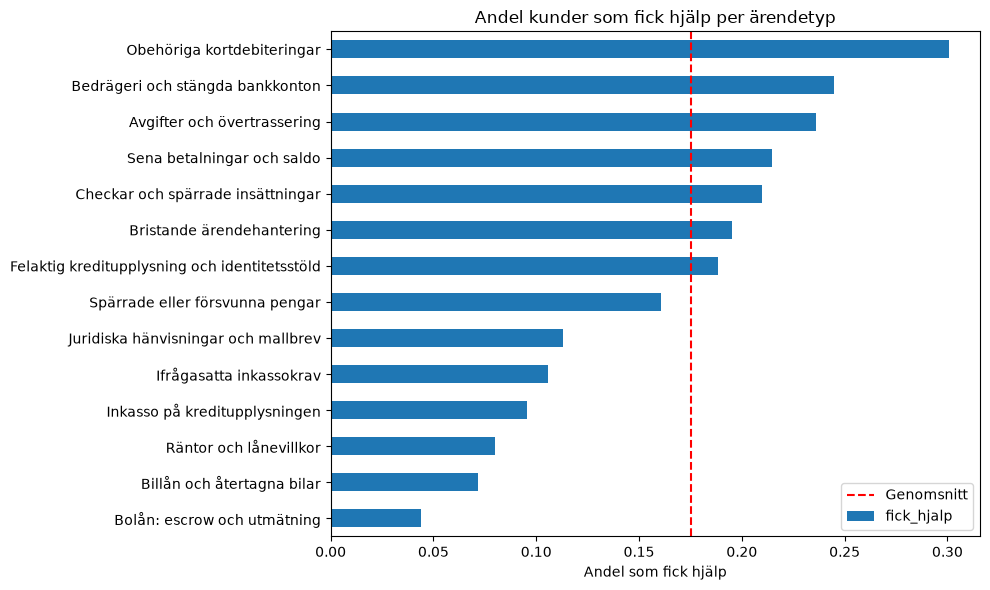

arendetyp
Bolån: escrow och utmätning                      0.044
Billån och återtagna bilar                       0.072
Räntor och lånevillkor                           0.080
Inkasso på kreditupplysningen                    0.095
Ifrågasatta inkassokrav                          0.106
Juridiska hänvisningar och mallbrev              0.113
Spärrade eller försvunna pengar                  0.161
Felaktig kreditupplysning och identitetsstöld    0.188
Bristande ärendehantering                        0.195
Checkar och spärrade insättningar                0.210
Sena betalningar och saldo                       0.214
Avgifter och övertrassering                      0.236
Bedrägeri och stängda bankkonton                 0.245
Obehöriga kortdebiteringar                       0.301
Name: fick_hjalp, dtype: float64


In [7]:
from scipy.stats import chi2_contingency

klusternamn = {
    0: "Bedrägeri och stängda bankkonton",
    1: "Spärrade eller försvunna pengar",
    2: "Bristande ärendehantering",
    3: "Obehöriga kortdebiteringar",
    4: "Juridiska hänvisningar och mallbrev",
    5: "Ifrågasatta inkassokrav",
    6: "Sena betalningar och saldo",
    7: "Räntor och lånevillkor",
    8: "Inkasso på kreditupplysningen",
    9: "Bolån: escrow och utmätning",
    10: "Billån och återtagna bilar",
    11: "Felaktig kreditupplysning och identitetsstöld",
    12: "Checkar och spärrade insättningar",
    13: "Avgifter och övertrassering",
}
df["arendetyp"] = df["kluster14"].map(klusternamn)

def chi2_test(kolumn):
    tabell = pd.crosstab(df[kolumn], df["fick_hjalp"])
    chi2, p, dof, _ = chi2_contingency(tabell)
    v = np.sqrt(chi2 / (tabell.values.sum() * (min(tabell.shape) - 1)))
    print(f"{kolumn}: chi² = {chi2:,.0f}, df = {dof}, p = {p:.2e}, Cramér's V = {v:.3f}")

chi2_test("arendetyp")
chi2_test("Product")

# Andel som fick hjälp per ärendetyp
andel = df.groupby("arendetyp")["fick_hjalp"].mean().sort_values()

fig, ax = plt.subplots(figsize=(10, 6))
andel.plot.barh(ax=ax, color="tab:blue")
ax.axvline(df["fick_hjalp"].mean(), color="red", linestyle="--", label="Genomsnitt")
ax.set_xlabel("Andel som fick hjälp")
ax.set_ylabel("")
ax.set_title("Andel kunder som fick hjälp per ärendetyp")
ax.legend()
plt.tight_layout()
plt.show()

print(andel.round(3))

**Resultat:**

| Indelning | Chi² | df | p | Cramér's V |
|---|---|---|---|---|
| Ärendetyp (klustring) | 3 566 | 13 | < 0,001 | 0,188 |
| Produkt (CFPB) | 5 895 | 7 | < 0,001 | 0,241 |

- H₀ förkastas: andelen som får hjälp skiljer sig mellan ärendetyperna. Sambandet är svagt till måttligt (Cramér's V = 0,188).
- **Ärendetyperna förklarar utfallet något sämre än produktindelningen** (V = 0,188 mot 0,241). En trolig förklaring är att företagens svar styrs mer av vilka regler som gäller för produkten än av vad kunden beskriver i sin text.
- **Tydligt mönster:** kunder får oftast hjälp när ärendet gäller en enskild transaktion som går att backa, t.ex. obehöriga kortdebiteringar (30 %), bedrägeri (25 %) och avgifter (24 %). Minst hjälp får de vid ärenden om avtal och långa förlopp, t.ex. bolån (4 %), billån (7 %), räntor och lånevillkor (8 %) och inkasso (10–11 %).
- *Juridiska hänvisningar och mallbrev* ger lägre chans till hjälp (11 %) än genomsnittet (17,5 %). Att citera lagtext verkar alltså inte hjälpa kunden.

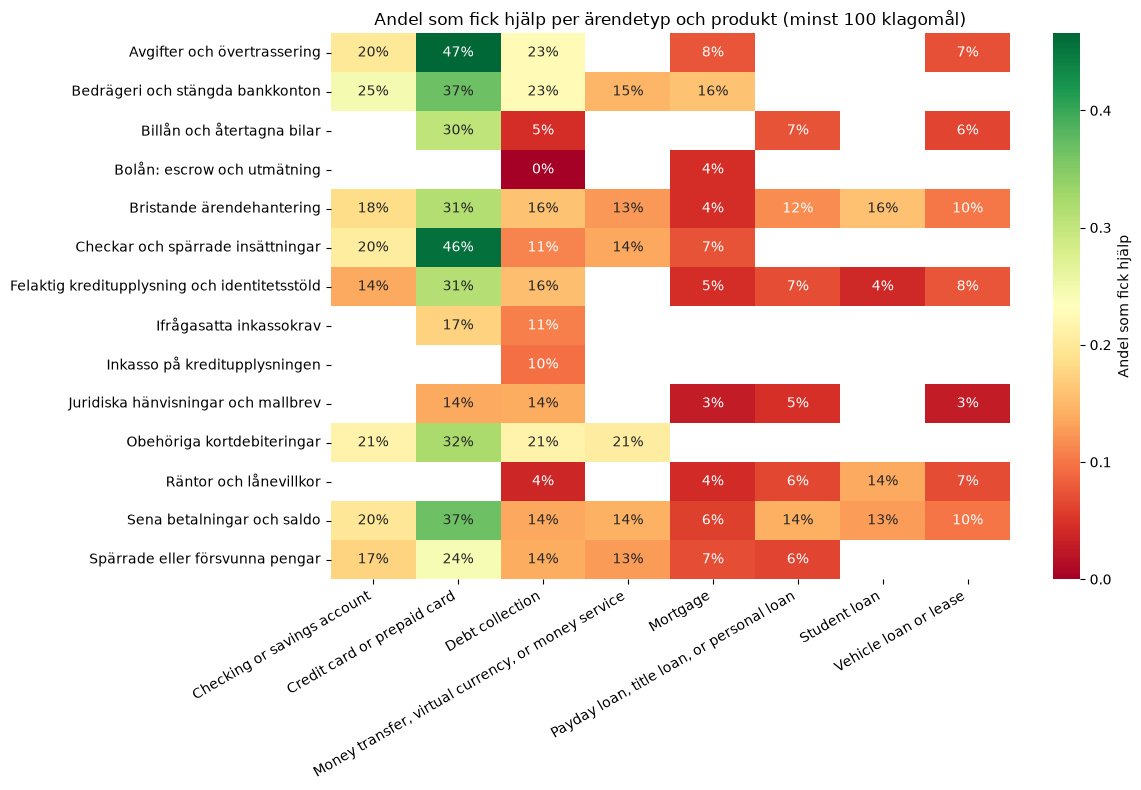

In [8]:
import seaborn as sns

pivot = df.pivot_table(index="arendetyp", columns="Product", values="fick_hjalp", aggfunc="mean")
antal = df.pivot_table(index="arendetyp", columns="Product", values="fick_hjalp", aggfunc="size")
pivot = pivot.where(antal >= 100)   # visa bara kombinationer med minst 100 klagomål

fig, ax = plt.subplots(figsize=(12, 8))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="RdYlGn", ax=ax,
            cbar_kws={"label": "Andel som fick hjälp"})
ax.set_title("Andel som fick hjälp per ärendetyp och produkt (minst 100 klagomål)")
ax.set_xlabel("")
ax.set_ylabel("")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

**Tillför ärendetyperna något utöver produkten?**

Heatmapen visar andelen som fick hjälp för varje kombination av ärendetyp och produkt (minst 100 klagomål).

- **Ja, särskilt för kreditkort.** Inom samma produkt varierar andelen från 14 % (juridiska hänvisningar) till 47 % (avgifter och övertrassering). Även för inkasso (4–23 %) och bolån (3–16 %) finns tydliga skillnader mellan ärendetyper.
- **Produkten har en egen, stark effekt.** Kreditkortsklagomål leder till hjälp oftare än genomsnittet för nästan alla ärendetyper, medan bolåneklagomål sällan gör det oavsett ärendetyp.
- **Juridiska hänvisningar och mallbrev ligger lågt inom varje produkt** (3–14 %). Fyndet beror alltså inte på att de klagomålen är vanligare för vissa produkter.

**Svar på affärsfrågan:** klustringen hittar 14 ärendetyper som går att tolka, och flera av dem går på tvärs av CFPB:s produktindelning. Produkten förklarar ensam mer av utfallet (Cramér's V 0,241 mot 0,188), men ärendetypen ger viktig information *inom* varje produkt. För en kundservicechef betyder det att både produkt och ärendetyp behövs för att förutse vilka ärenden som leder till kompensation.

### Spara resultat
Datan med klusteretiketter sparas för metodjämförelsen och appen.

In [9]:
df.to_parquet("../data/complaints_kmeans.parquet")

### Spara modell och data till appen

Den tränade modellen (TF-IDF, LSA och K-means) sparas tillsammans med klustrens namn och nyckelord, så att appen kan sortera nya klagomål utan att träna om modellen.

För att appen ska kunna köras direkt från repot sparas också:
- **en sammanfattad tabell** med antal klagomål och andel som fick hjälp per månad, ärendetyp, produkt och företag (de 15 största företagen, övriga sammanslagna)
- **5 000 slumpmässigt valda klagomål** med sina LSA-vektorer, som används för att visa liknande klagomål

Filerna sparas i `app/resurser/`.

In [10]:
import joblib
from pathlib import Path

ut = Path("../app/resurser")
ut.mkdir(parents=True, exist_ok=True)

# Modellen
joblib.dump(vec, ut / "tfidf.joblib")
joblib.dump(lsa, ut / "lsa.joblib")
joblib.dump(km14, ut / "kmeans14.joblib")
joblib.dump(klusternamn, ut / "klusternamn.joblib")

# Nyckelord per kluster
centra = lsa[0].inverse_transform(km14.cluster_centers_)
nyckelord = {klusternamn[i]: list(ord_lista[centra[i].argsort()[::-1][:10]]) for i in range(14)}
joblib.dump(nyckelord, ut / "nyckelord.joblib")

# Sammanfattad data för översikten
topp_foretag = df["Company"].value_counts().head(15).index
agg = (
    df.assign(
        manad=df["Date received"].dt.to_period("M").dt.to_timestamp(),
        foretag=df["Company"].where(df["Company"].isin(topp_foretag), "Övriga"),
    )
    .groupby(["manad", "arendetyp", "Product", "foretag"])
    .agg(antal=("fick_hjalp", "size"), fick_hjalp=("fick_hjalp", "sum"))
    .reset_index()
)
agg.to_parquet(ut / "aggregat.parquet")

# 5 000 exempelklagomål med LSA-vektorer (positionsbaserat urval så att rader och vektorer matchar)
pos = np.random.default_rng(42).choice(len(df), size=5_000, replace=False)
exempel = df.iloc[pos][["Consumer complaint narrative", "arendetyp", "Product", "fick_hjalp"]].reset_index(drop=True)
exempel.to_parquet(ut / "exempel.parquet")
np.save(ut / "exempel_lsa.npy", X_lsa[pos].astype("float32"))

# Kontroll
for f in sorted(ut.iterdir()):
    print(f"{f.name:25s} {f.stat().st_size / 1e6:6.1f} MB")
print("\nRader i sammanfattad tabell:", len(agg))

aggregat.parquet             0.0 MB
exempel.parquet              3.3 MB
exempel_lsa.npy              2.0 MB
klusternamn.joblib           0.0 MB
kmeans14.joblib              0.4 MB
lsa.joblib                   7.4 MB
nyckelord.joblib             0.0 MB
tfidf.joblib                 0.2 MB

Rader i sammanfattad tabell: 5588
